### MODELING

**DOWNLOAD ME**

Using your visualizations from last week, create a basic model!

In [6]:
# Run me!
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsClassifier

# google colab users: uncomment below
# from google.colab import files

In [3]:
# Google Colab users uncomment the line below:
# uploaded = files.upload()

In [10]:
def season_totals(path):
    data = pd.read_csv(path)
    data["_season_total"] = data["Team"].astype(str).str.fullmatch(r"\d+TM", na=False)
    return (
        data.sort_values("_season_total", ascending=False)
        .drop_duplicates(subset="Player")
        .drop(columns="_season_total")
    )

rushing = season_totals("2024RushingData.csv")[["Player", "Team", "Pos", "Att", "Yds", "TD", "1D", "Fmb"]].rename(
    columns={
        "Team": "RushTeam",
        "Pos": "RushPos",
        "Att": "RushAtt",
        "Yds": "RushYds",
        "TD": "RushTD",
        "1D": "Rush1D",
        "Fmb": "RushFmb",
    }
)
receiving = season_totals("2024ReceivingData.csv")[["Player", "Team", "Pos", "Tgt", "Rec", "Yds", "TD", "1D", "Fmb"]].rename(
    columns={
        "Team": "ReceiveTeam",
        "Pos": "ReceivePos",
        "Tgt": "ReceiveTgt",
        "Rec": "ReceiveRec",
        "Yds": "ReceiveYds",
        "TD": "ReceiveTD",
        "1D": "Receive1D",
        "Fmb": "ReceiveFmb",
    }
)
passing = season_totals("2024PassingData.csv")[["Player", "Team", "Pos", "G", "Cmp", "Att", "Yds", "TD", "Int"]].rename(
    columns={
        "Team": "PassTeam",
        "Pos": "PassPos",
        "G": "PassG",
        "Cmp": "PassCmp",
        "Att": "PassAtt",
        "Yds": "PassYds",
        "TD": "PassTD",
        "Int": "Int",
    }
)

df = rushing.merge(receiving, on="Player", how="outer").merge(passing, on="Player", how="outer")
df["Team"] = df["RushTeam"].combine_first(df["ReceiveTeam"]).combine_first(df["PassTeam"])
df["Pos"] = df["RushPos"].combine_first(df["ReceivePos"]).combine_first(df["PassPos"])
df = df.drop(columns=["RushTeam", "ReceiveTeam", "PassTeam", "RushPos", "ReceivePos", "PassPos"])
df["year"] = 2024

df["FantasyPoints"] = (
    df["PassYds"].fillna(0) * 0.04
    + df["PassTD"].fillna(0) * 4
    - df["Int"].fillna(0) * 2
    + df["RushYds"].fillna(0) * 0.1
    + df["ReceiveYds"].fillna(0) * 0.1
    + (df["RushTD"].fillna(0) + df["ReceiveTD"].fillna(0)) * 6
    - (df["RushFmb"].fillna(0) + df["ReceiveFmb"].fillna(0)) * 2
)

In [11]:
# For each table, print out the first couple rows:
df.head()

,Player,RushAtt,RushYds,RushTD,Rush1D,RushFmb,ReceiveTgt,ReceiveRec,ReceiveYds,ReceiveTD,...,PassG,PassCmp,PassAtt,PassYds,PassTD,Int,Team,Pos,year,FantasyPoints
0,A.J. Brown,0.0,0.0,0.0,0.0,0.0,97.0,67.0,1079.0,7.0,...,NaN,NaN,NaN,NaN,NaN,NaN,PHI,WR,2024,149.90
1,AJ Barner,0.0,0.0,0.0,0.0,0.0,38.0,30.0,245.0,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,SEA,TE,2024,48.50
2,AJ Cole III,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,17.0,1.0,1.0,34.0,0.0,0.0,LVR,P,2024,1.36
3,Aaron Jones,255.0,1138.0,5.0,50.0,5.0,62.0,51.0,408.0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,MIN,RB,2024,176.60
4,Aaron Rodgers,22.0,107.0,0.0,7.0,5.0,NaN,NaN,NaN,NaN,...,17.0,368.0,584.0,3897.0,28.0,11.0,NYJ,QB,2024,246.58


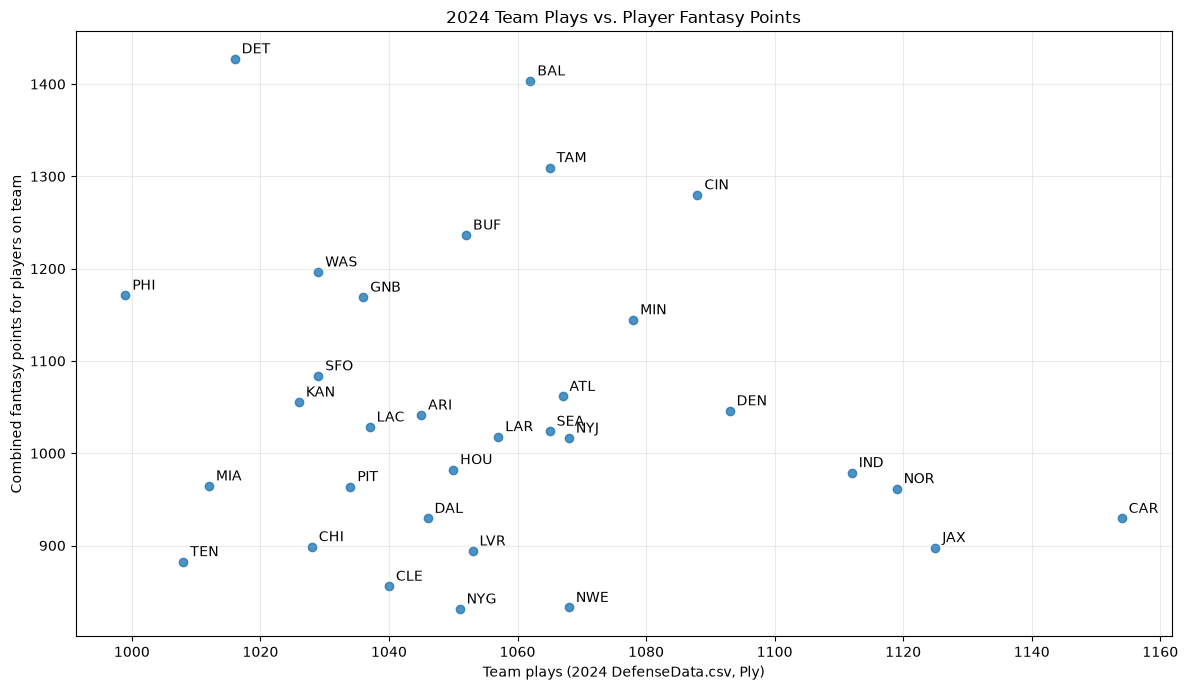

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

team_codes = {
    "Arizona Cardinals": "ARI",
    "Atlanta Falcons": "ATL",
    "Baltimore Ravens": "BAL",
    "Buffalo Bills": "BUF",
    "Carolina Panthers": "CAR",
    "Chicago Bears": "CHI",
    "Cincinnati Bengals": "CIN",
    "Cleveland Browns": "CLE",
    "Dallas Cowboys": "DAL",
    "Denver Broncos": "DEN",
    "Detroit Lions": "DET",
    "Green Bay Packers": "GNB",
    "Houston Texans": "HOU",
    "Indianapolis Colts": "IND",
    "Jacksonville Jaguars": "JAX",
    "Kansas City Chiefs": "KAN",
    "Las Vegas Raiders": "LVR",
    "Los Angeles Chargers": "LAC",
    "Los Angeles Rams": "LAR",
    "Miami Dolphins": "MIA",
    "Minnesota Vikings": "MIN",
    "New England Patriots": "NWE",
    "New Orleans Saints": "NOR",
    "New York Giants": "NYG",
    "New York Jets": "NYJ",
    "Philadelphia Eagles": "PHI",
    "Pittsburgh Steelers": "PIT",
    "San Francisco 49ers": "SFO",
    "Seattle Seahawks": "SEA",
    "Tampa Bay Buccaneers": "TAM",
    "Tennessee Titans": "TEN",
    "Washington Commanders": "WAS",
}

rushing_by_team = pd.read_csv("2024RushingData.csv")
rushing_by_team = rushing_by_team.loc[
    ~rushing_by_team["Team"].astype(str).str.fullmatch(r"\d+TM", na=False),
    ["Player", "Team", "Att", "Yds", "TD", "Fmb"],
].rename(columns={"Att": "RushAtt", "Yds": "RushYds", "TD": "RushTD", "Fmb": "RushFmb"})

receiving_by_team = pd.read_csv("2024ReceivingData.csv")
receiving_by_team = receiving_by_team.loc[
    ~receiving_by_team["Team"].astype(str).str.fullmatch(r"\d+TM", na=False),
    ["Player", "Team", "Yds", "TD", "Fmb"],
].rename(columns={"Yds": "ReceiveYds", "TD": "ReceiveTD", "Fmb": "ReceiveFmb"})

passing_by_team = pd.read_csv("2024PassingData.csv")
passing_by_team = passing_by_team.loc[
    ~passing_by_team["Team"].astype(str).str.fullmatch(r"\d+TM", na=False),
    ["Player", "Team", "Att", "Yds", "TD", "Int", "Sk"],
].rename(columns={"Att": "PassAtt", "Yds": "PassYds", "TD": "PassTD", "Sk": "PassSk"})

player_team_stats = rushing_by_team.merge(receiving_by_team, on=["Player", "Team"], how="outer")
player_team_stats = player_team_stats.merge(passing_by_team, on=["Player", "Team"], how="outer")
stat_columns = [
    "RushAtt", "RushYds", "RushTD", "RushFmb", "ReceiveYds", "ReceiveTD",
    "ReceiveFmb", "PassAtt", "PassYds", "PassTD", "Int", "PassSk",
]
player_team_stats[stat_columns] = player_team_stats[stat_columns].fillna(0)
player_team_stats["FantasyPoints"] = (
    player_team_stats["PassYds"] * 0.04
    + player_team_stats["PassTD"] * 4
    - player_team_stats["Int"] * 2
    + player_team_stats["RushYds"] * 0.1
    + player_team_stats["ReceiveYds"] * 0.1
    + (player_team_stats["RushTD"] + player_team_stats["ReceiveTD"]) * 6
    - player_team_stats[["RushFmb", "ReceiveFmb"]].max(axis=1) * 2
)
team_fantasy_points = player_team_stats.groupby("Team", as_index=False)["FantasyPoints"].sum()

team_plays = pd.read_csv("2024DefenseData.csv")[["Tm", "Ply"]].rename(
    columns={"Tm": "TeamName", "Ply": "TeamPlays"}
)
team_plays["Team"] = team_plays["TeamName"].map(team_codes)
team_plays["TeamPlays"] = pd.to_numeric(team_plays["TeamPlays"], errors="coerce")
plot_data = team_plays.merge(team_fantasy_points, on="Team", how="inner")

plt.figure(figsize=(12, 7))
plt.scatter(plot_data["TeamPlays"], plot_data["FantasyPoints"], alpha=0.8)
for _, team in plot_data.iterrows():
    plt.annotate(
        team["Team"],
        (team["TeamPlays"], team["FantasyPoints"]),
        xytext=(5, 4),
        textcoords="offset points",
    )
plt.xlabel("Team plays (2024 DefenseData.csv, Ply)")
plt.ylabel("Combined fantasy points for players on team")
plt.title("2024 Team Plays vs. Player Fantasy Points")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

What question do you want to use regression or classification for? Answer:

Can the number of plays faced by a team's defense predict the combined fantasy points scored by players on that team in 2024?

What is your response variable? Answer:

The response variable is each team's combined 2024 player fantasy points (`FantasyPoints`).

What variables do you want to use for prediction/classification? Think back to the visualizations you made last week for ideas of what correlates!

Answer:

Use the number of plays faced by each team's defense (`TeamPlays`, from the `Ply` column of `2024DefenseData.csv`) to predict that team's combined player fantasy points.

In [5]:
from sklearn.model_selection import train_test_split

X = plot_data[["TeamPlays"]]
y = plot_data["FantasyPoints"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Regression

If you want to do classification, skip this part! If not, work through this little section.

In [7]:
regr = LinearRegression()
regr.fit(X_train, y_train)
regr.score(X_test, y_test)
# predictions = regr.predict(X_test)

-0.5705332685978599

In [8]:
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)
ridge_model.score(X_test, y_test)
# predictions = ridge_model.predict(X_test)

-0.5705251548386485

In [9]:
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train, y_train)
lasso_model.score(X_test, y_test)
# predictions = lasso_model.predict(X_test)

-0.5705185877024823

Which model did the best? What could you do to improve this model for better accuracy on test data?

Answer:

Lasso had the highest test R-squared (about -0.5705), but it was only marginally higher than Ridge and linear regression. All three negative scores mean they performed worse than predicting the test-set average, so plays faced alone is not a useful predictor in this split. The sample contains only 32 teams; use more seasons, add relevant offensive predictors, and evaluate with cross-validation to get a more reliable model.

## Classification

Because fantasy points are continuous, this section classifies teams into two groups: below the 2024 median or at/above the 2024 median. Defense plays faced remains the predictor.

In [10]:
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

fantasy_point_median = plot_data["FantasyPoints"].median()
y_class = pd.Series(
    np.where(
        plot_data["FantasyPoints"] >= fantasy_point_median,
        "At/above median",
        "Below median",
    ),
    index=plot_data.index,
    name="FantasyClass",
)
X_class = plot_data[["TeamPlays"]]

X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X_class,
    y_class,
    test_size=0.25,
    random_state=42,
    stratify=y_class,
)

knn_cv_scores = {}
for k in range(1, 12):
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(knn, X_class_train, y_class_train, cv=LeaveOneOut())
    knn_cv_scores[k] = scores.mean()
    print(f"mean leave-one-out CV accuracy = {scores.mean():.3f} for k = {k}")

best_k = max(knn_cv_scores, key=knn_cv_scores.get)
knn_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
knn_model.fit(X_class_train, y_class_train)
knn_test_accuracy = knn_model.score(X_class_test, y_class_test)
print(f"Best k = {best_k}; held-out test accuracy = {knn_test_accuracy:.3f}")

mean leave-one-out CV accuracy = 0.583 for k = 1
mean leave-one-out CV accuracy = 0.500 for k = 2
mean leave-one-out CV accuracy = 0.583 for k = 3
mean leave-one-out CV accuracy = 0.500 for k = 4
mean leave-one-out CV accuracy = 0.375 for k = 5
mean leave-one-out CV accuracy = 0.333 for k = 6
mean leave-one-out CV accuracy = 0.500 for k = 7
mean leave-one-out CV accuracy = 0.500 for k = 8
mean leave-one-out CV accuracy = 0.583 for k = 9
mean leave-one-out CV accuracy = 0.375 for k = 10
mean leave-one-out CV accuracy = 0.375 for k = 11
Best k = 1; held-out test accuracy = 0.500


What k value did best? How do you know?

Answer:

k = 1, 3, and 9 tied for the best leave-one-out cross-validation accuracy at 0.583. The code selects the smallest tied value, k = 1. Its held-out test accuracy was 0.500.

In [13]:
from sklearn.linear_model import LogisticRegression

log = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42),
)
log.fit(X_class_train, y_class_train)
log_test_accuracy = log.score(X_class_test, y_class_test)
print(f"Logistic regression held-out test accuracy = {log_test_accuracy:.3f}")

Logistic regression held-out test accuracy = 0.500


What classifier did better? What could you do to improve the model for better accuracy on test data?

Answer:

Neither classifier did better on the held-out teams: k-NN (k = 1) and logistic regression both had 0.500 accuracy (4 of 8 teams). This is a small test set with only one predictor, so the result is uncertain. Add more seasons and relevant team/player features, then compare models with stratified cross-validation rather than relying on one split.